<a href="https://colab.research.google.com/github/MAI-AIIU/deep-learning/blob/main/src/sixth-week/multilayer-perceptrons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Metadata
**Name**  
> Naveed Ahmad Hematmal

**Assignment**    

> Multiplayer Perceptrons

# Implementation of Multilayer Perceptrons
:label:`sec_mlp-implementation`

This notebook implements multilayer perceptrons (MLPs) with PyTorch. It first builds a two-layer network by defining its parameters and forward pass, then shows the equivalent concise model with `nn.Sequential`. Both models are trained using a native PyTorch training loop.

In [1]:
import random

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

random.seed(0)
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Implementation from Scratch

### Initializing Model Parameters

Fashion-MNIST contains 10 classes, and each grayscale image has $28 \times 28 = 784$ pixels. We flatten each image and build an MLP with one hidden layer of 256 units. Every layer has a weight matrix and bias vector, registered as `nn.Parameter` so PyTorch autograd can compute their gradients.

The model below inherits directly from `torch.nn.Module`. Registering tensors as `nn.Parameter` makes them visible through `model.parameters()` and eligible for optimization.

In [2]:
class MLPScratch(nn.Module):
    def __init__(self, num_inputs=784, num_outputs=10, num_hiddens=256, sigma=0.01):
        super().__init__()
        self.num_inputs = num_inputs
        self.W1 = nn.Parameter(torch.randn(num_inputs, num_hiddens) * sigma)
        self.b1 = nn.Parameter(torch.zeros(num_hiddens))
        self.W2 = nn.Parameter(torch.randn(num_hiddens, num_outputs) * sigma)
        self.b2 = nn.Parameter(torch.zeros(num_outputs))

    def forward(self, X):
        X = X.reshape(X.shape[0], self.num_inputs)
        hidden = relu(X @ self.W1 + self.b1)
        return hidden @ self.W2 + self.b2

### Model

To make the computation explicit, we define the ReLU activation as $\mathrm{ReLU}(x) = \max(0, x)$.

In [3]:
def relu(X):
    return torch.clamp_min(X, 0)

Instantiate the model and check the output shape. The output contains one unnormalized score (logit) per class.

In [4]:
scratch_model = MLPScratch().to(device)
sample_batch = torch.rand(4, 1, 28, 28, device=device)
scratch_model(sample_batch).shape

torch.Size([4, 10])

### Training

Load Fashion-MNIST directly with `torchvision` and use PyTorch `DataLoader` objects for minibatching. The training function below uses `CrossEntropyLoss`, autograd, and SGD, and reports the loss and accuracy on both splits after every epoch.

In [5]:
batch_size = 256
num_epochs = 10
learning_rate = 0.1

transform = transforms.ToTensor()
train_dataset = datasets.FashionMNIST(root="../data", train=True, transform=transform, download=True)
test_dataset = datasets.FashionMNIST(root="../data", train=False, transform=transform, download=True)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)


def evaluate(model, data_loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.no_grad():
        for images, targets in data_loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            total_loss += F.cross_entropy(logits, targets, reduction="sum").item()
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += targets.shape[0]
    return total_loss / total_examples, total_correct / total_examples


def train_model(model, train_loader, test_loader, epochs=10, lr=0.1):
    model = model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_accuracy": [], "test_loss": [], "test_accuracy": []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_correct = 0
        total_examples = 0
        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = F.cross_entropy(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * targets.shape[0]
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += targets.shape[0]

        train_loss = total_loss / total_examples
        train_accuracy = total_correct / total_examples
        test_loss, test_accuracy = evaluate(model, test_loader)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)
        print(
            f"Epoch {epoch + 1:2d}/{epochs} | "
            f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
            f"test loss {test_loss:.4f}, accuracy {test_accuracy:.2%}"
        )
    return history


scratch_model = MLPScratch(num_hiddens=256)
scratch_history = train_model(
    scratch_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 14.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 210kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.92MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 28.6MB/s]


Epoch  1/10 | train loss 1.0503, accuracy 63.28% | test loss 0.7236, accuracy 75.14%
Epoch  2/10 | train loss 0.5988, accuracy 79.04% | test loss 0.6090, accuracy 77.58%
Epoch  3/10 | train loss 0.5183, accuracy 81.96% | test loss 0.5101, accuracy 82.24%
Epoch  4/10 | train loss 0.4820, accuracy 83.16% | test loss 0.5466, accuracy 80.96%
Epoch  5/10 | train loss 0.4589, accuracy 83.89% | test loss 0.5221, accuracy 81.55%
Epoch  6/10 | train loss 0.4356, accuracy 84.73% | test loss 0.4608, accuracy 83.79%
Epoch  7/10 | train loss 0.4182, accuracy 85.30% | test loss 0.4674, accuracy 83.10%
Epoch  8/10 | train loss 0.4043, accuracy 85.70% | test loss 0.4300, accuracy 84.93%
Epoch  9/10 | train loss 0.3942, accuracy 86.10% | test loss 0.4244, accuracy 84.88%
Epoch 10/10 | train loss 0.3831, accuracy 86.56% | test loss 0.4444, accuracy 83.58%


## Concise Implementation

The same network can be expressed with built-in PyTorch layers. `Flatten` preserves the batch dimension, and the fully connected layers and ReLU perform the same transformations as `MLPScratch`.

In [6]:
class MLP(nn.Module):
    def __init__(self, num_outputs=10, num_hiddens=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, num_hiddens),
            nn.ReLU(),
            nn.Linear(num_hiddens, num_outputs),
        )

    def forward(self, X):
        return self.net(X)

`nn.Sequential` applies each layer in order, so the concise model needs only to define its sequence. We train it with the same function and data loaders as the scratch implementation, making the architectures directly comparable.

In [7]:
concise_model = MLP(num_outputs=10, num_hiddens=256)
concise_history = train_model(
    concise_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

Epoch  1/10 | train loss 0.8697, accuracy 71.34% | test loss 0.7197, accuracy 74.14%
Epoch  2/10 | train loss 0.5590, accuracy 80.67% | test loss 0.6123, accuracy 76.41%
Epoch  3/10 | train loss 0.4980, accuracy 82.52% | test loss 0.5772, accuracy 78.24%
Epoch  4/10 | train loss 0.4616, accuracy 83.76% | test loss 0.4919, accuracy 82.72%
Epoch  5/10 | train loss 0.4384, accuracy 84.64% | test loss 0.4677, accuracy 83.35%
Epoch  6/10 | train loss 0.4199, accuracy 85.22% | test loss 0.4462, accuracy 84.39%
Epoch  7/10 | train loss 0.4035, accuracy 85.84% | test loss 0.4291, accuracy 84.70%
Epoch  8/10 | train loss 0.3913, accuracy 86.25% | test loss 0.4716, accuracy 83.70%
Epoch  9/10 | train loss 0.3807, accuracy 86.58% | test loss 0.4185, accuracy 85.10%
Epoch 10/10 | train loss 0.3711, accuracy 86.91% | test loss 0.4634, accuracy 82.85%


## Summary

Both implementations represent the same two-layer MLP. The scratch model exposes parameter tensors and the forward computation; the concise model uses `nn.Linear`, `nn.ReLU`, and `nn.Sequential`. Both use the same PyTorch data loaders, cross-entropy objective, autograd, SGD optimizer, and evaluation loop.

## Exercises

1. Change `num_hiddens` and compare the test accuracy of the scratch and concise models.
2. Add another hidden layer to each implementation and compare the results.
<!-- 1. Why might a hidden layer with a single neuron limit what the network can learn? -->
3. Change the learning rate and number of epochs. Plot or compare the losses and accuracies in `scratch_history` and `concise_history`.
4. Compare other activation functions and weight initializations.
<!-- 1. Compare training speed for the two implementations on CPU and, when available, GPU.

**Setup:** Requires PyTorch, torchvision, and matplotlib. Fashion-MNIST is downloaded into `../data` the first time the dataset cell runs. -->

## Solution

### 1: Change num_hiddens and compare the test accuracy of the scratch and concise models.

In below code I am increase the number of hidden perceptron and at end comparing all solutions to see how increaseing perceptron affect performance and accuracy

In [8]:
results = {}

for hidden in [64, 128, 256, 512, 1024]:
    print(f"\nTraining MLP with {hidden} hidden neurons")

    model = MLPScratch(num_hiddens=hidden)

    history = train_model(
        model,
        train_loader,
        test_loader,
        epochs=num_epochs,
        lr=learning_rate
    )

    results[hidden] = history


Training MLP with 64 hidden neurons
Epoch  1/10 | train loss 1.1461, accuracy 58.56% | test loss 0.8367, accuracy 67.57%
Epoch  2/10 | train loss 0.6370, accuracy 77.30% | test loss 0.7592, accuracy 72.79%
Epoch  3/10 | train loss 0.5370, accuracy 81.34% | test loss 0.5652, accuracy 79.88%
Epoch  4/10 | train loss 0.4935, accuracy 82.72% | test loss 0.4918, accuracy 82.64%
Epoch  5/10 | train loss 0.4689, accuracy 83.57% | test loss 0.6858, accuracy 73.93%
Epoch  6/10 | train loss 0.4471, accuracy 84.37% | test loss 0.4756, accuracy 82.97%
Epoch  7/10 | train loss 0.4302, accuracy 84.87% | test loss 0.5223, accuracy 79.93%
Epoch  8/10 | train loss 0.4153, accuracy 85.44% | test loss 0.4493, accuracy 84.00%
Epoch  9/10 | train loss 0.4043, accuracy 85.81% | test loss 0.4760, accuracy 83.72%
Epoch 10/10 | train loss 0.3930, accuracy 86.17% | test loss 0.4463, accuracy 83.91%

Training MLP with 128 hidden neurons
Epoch  1/10 | train loss 1.1003, accuracy 61.25% | test loss 0.7340, accura

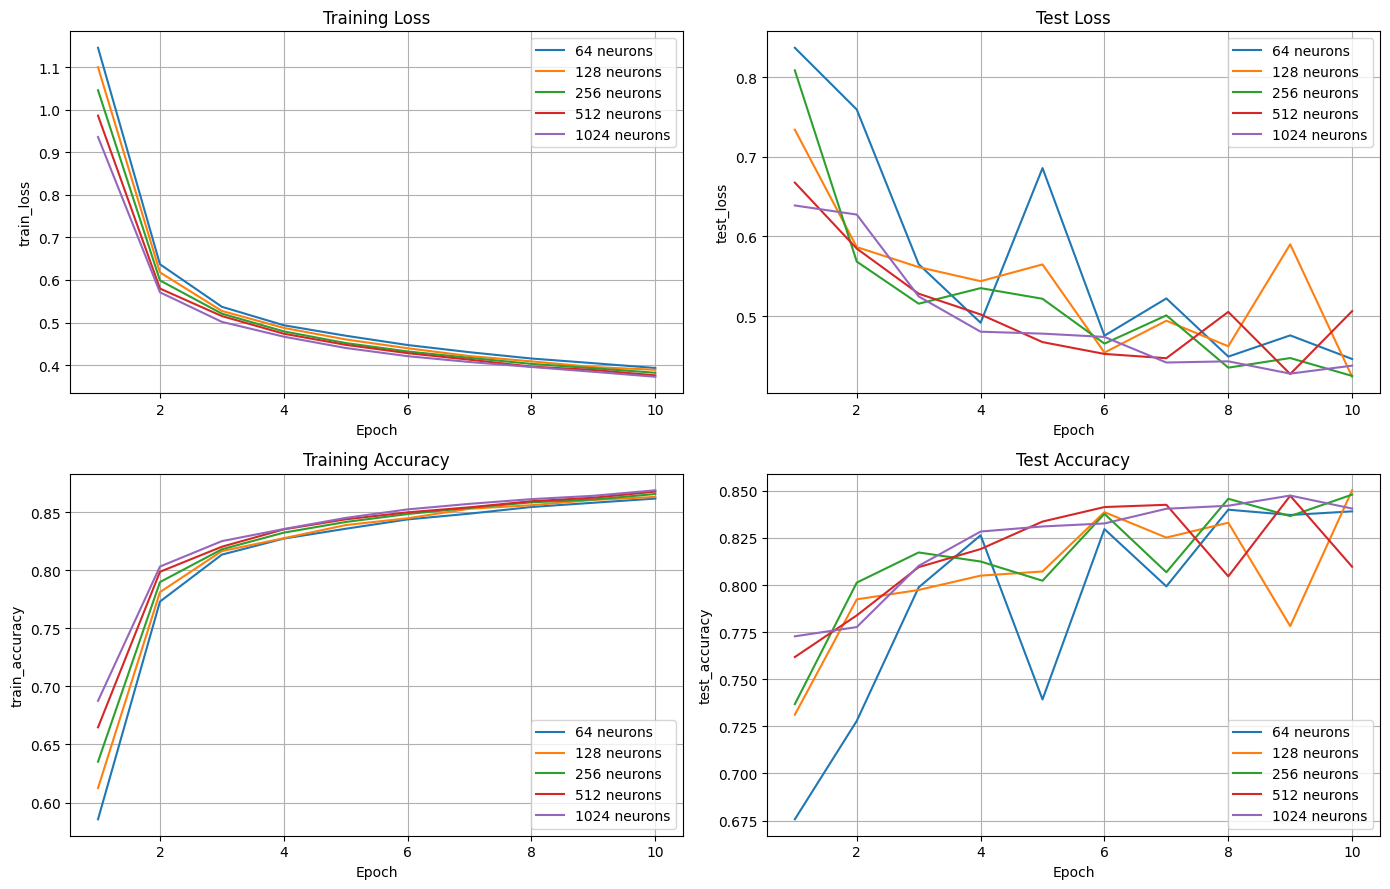

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

metrics = [
    ("train_loss", "Training Loss"),
    ("test_loss", "Test Loss"),
    ("train_accuracy", "Training Accuracy"),
    ("test_accuracy", "Test Accuracy")
]

for ax, (metric, title) in zip(axes.flat, metrics):
    for hidden, history in results.items():
        ax.plot(
            range(1, len(history[metric]) + 1),
            history[metric],
            label=f"{hidden} neurons"
        )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric)
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 3: Add another hidden layer to each implementation and compare the results.

Here adding one more hidden layer to below implementation and comparing with it.

In [10]:
class MLP(nn.Module):
    def __init__(self, num_outputs=10, num_hiddens=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, num_hiddens),
            nn.ReLU(),
            nn.Linear(num_hiddens, num_outputs),
        )

    def forward(self, X):
        return self.net(X)

concise_model = MLP(num_outputs=10, num_hiddens=256)
concise_history = train_model(
    concise_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

Epoch  1/10 | train loss 0.8689, accuracy 71.38% | test loss 0.6463, accuracy 76.27%
Epoch  2/10 | train loss 0.5594, accuracy 80.62% | test loss 0.5785, accuracy 79.42%
Epoch  3/10 | train loss 0.4994, accuracy 82.52% | test loss 0.5024, accuracy 82.31%
Epoch  4/10 | train loss 0.4610, accuracy 83.84% | test loss 0.6545, accuracy 74.91%
Epoch  5/10 | train loss 0.4426, accuracy 84.59% | test loss 0.4504, accuracy 84.20%
Epoch  6/10 | train loss 0.4212, accuracy 85.24% | test loss 0.4463, accuracy 84.33%
Epoch  7/10 | train loss 0.4062, accuracy 85.76% | test loss 0.4504, accuracy 83.96%
Epoch  8/10 | train loss 0.3966, accuracy 86.05% | test loss 0.4340, accuracy 84.72%
Epoch  9/10 | train loss 0.3845, accuracy 86.50% | test loss 0.4121, accuracy 85.23%
Epoch 10/10 | train loss 0.3749, accuracy 86.74% | test loss 0.4467, accuracy 84.03%


In [11]:
class MLP(nn.Module):
    def __init__(self, num_outputs=10, num_hiddens=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, num_hiddens),
            nn.ReLU(),
            nn.Linear(num_hiddens, num_hiddens),
            nn.ReLU(),
            nn.Linear(num_hiddens, num_outputs),
        )

    def forward(self, X):
        return self.net(X)

concise_model = MLP(num_outputs=10, num_hiddens=256)
concise_history = train_model(
    concise_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

Epoch  1/10 | train loss 1.0047, accuracy 65.32% | test loss 0.7356, accuracy 71.70%
Epoch  2/10 | train loss 0.5783, accuracy 79.39% | test loss 0.6879, accuracy 77.97%
Epoch  3/10 | train loss 0.4955, accuracy 82.36% | test loss 0.5101, accuracy 81.84%
Epoch  4/10 | train loss 0.4572, accuracy 83.80% | test loss 0.4781, accuracy 82.98%
Epoch  5/10 | train loss 0.4273, accuracy 84.65% | test loss 0.4372, accuracy 84.42%
Epoch  6/10 | train loss 0.4080, accuracy 85.34% | test loss 0.4432, accuracy 84.09%
Epoch  7/10 | train loss 0.3887, accuracy 86.02% | test loss 0.5784, accuracy 79.86%
Epoch  8/10 | train loss 0.3721, accuracy 86.56% | test loss 0.4191, accuracy 85.08%
Epoch  9/10 | train loss 0.3625, accuracy 86.79% | test loss 0.4156, accuracy 84.93%
Epoch 10/10 | train loss 0.3501, accuracy 87.28% | test loss 0.4386, accuracy 83.53%


### Compare other activation functions and weight initializations.

I change the `ReLU` to `tanh` activation function, and also initializing weights with other values, I am using concise implementation and making my changes on it.

In [12]:
class MLP(nn.Module):
    def __init__(self, num_outputs=10, num_hiddens=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, num_hiddens),
            nn.Tanh(),
            nn.Linear(num_hiddens, num_outputs),
        )

        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, X):
        return self.net(X)

In [13]:
concise_model = MLP(num_outputs=10, num_hiddens=256)
concise_history = train_model(
    concise_model, train_loader, test_loader, epochs=num_epochs, lr=learning_rate
)

Epoch  1/10 | train loss 0.6906, accuracy 76.41% | test loss 0.5594, accuracy 80.36%
Epoch  2/10 | train loss 0.5003, accuracy 82.39% | test loss 0.6095, accuracy 80.05%
Epoch  3/10 | train loss 0.4612, accuracy 83.65% | test loss 0.5222, accuracy 80.49%
Epoch  4/10 | train loss 0.4369, accuracy 84.37% | test loss 0.5012, accuracy 80.83%
Epoch  5/10 | train loss 0.4211, accuracy 85.02% | test loss 0.4390, accuracy 84.32%
Epoch  6/10 | train loss 0.4088, accuracy 85.40% | test loss 0.4352, accuracy 84.30%
Epoch  7/10 | train loss 0.3976, accuracy 85.81% | test loss 0.4722, accuracy 82.61%
Epoch  8/10 | train loss 0.3862, accuracy 86.27% | test loss 0.4159, accuracy 85.09%
Epoch  9/10 | train loss 0.3820, accuracy 86.33% | test loss 0.4313, accuracy 84.44%
Epoch 10/10 | train loss 0.3730, accuracy 86.70% | test loss 0.4177, accuracy 85.03%


In above code only `nn.Linear` layers weights are initialized, as activation function and flatten doesn't have trainable weights, and for the weights initialization the Xavier method is used, and there are several for that.